# Modelagem do problema da coloração Grundy
> Autores: 
> - Gustavo Gurgel Medeiros - 539226
> - Mário Martins Aragão - 542056
---

### <span style="color:red">Instale essa libs antes de rodar os códigos</span>
> pip install ortools networkx matplotlib graphviz

## Códigos auxiliares
---

In [1]:
from ortools.linear_solver import pywraplp
import networkx as nx
import random
from graphviz import Source
from IPython.display import Image

graphVizTemplate = '\
graph G {\n\
node [shape = "circle", fontcolor="black", style=filled, color="black"]\n\
A [style=invis]\n\
'

# Mostra um grafo utilizando o graphfiz
def display_graphviz(graph_str):
    graph = Source(graph_str)
    return graph.render(view=True)

# Gerar n cores aleatórias
def gerar_cores_aleatorias(n):
  cores = set()  
  while len(cores) < n:
    cor = f"#{random.randint(0, 0xFFFFFF):06x}"
    cores.add(cor)
  
  return list(cores)

# Desenhar o grafo com o vetor de cores y
def gdrawGraph(G, y, mode): 
    n = len(G.nodes)
    out = graphVizTemplate
    cores_aleatorias = gerar_cores_aleatorias(n)

    for v in range(n):
        for c in range(n):
            if y[v, c].solution_value() == 1:
              if mode == "c":
                out += '{}[label="{}", fillcolor="{}"]\n'.format(str(v), c, cores_aleatorias[c])
              elif mode == "n":
                out += '{}[label="{}", fillcolor="{}"]\n'.format(str(v), v, cores_aleatorias[c])
              elif mode == "cn" or mode == "nc":
                out += '{}[label="{}", fillcolor="{}"]\n'.format(str(v), "v: " + str(v) + " | " + "c: " + str(c) + "\n penis", cores_aleatorias[c])
              elif mode == "cnx" or mode == "ncx":
                c_neighbors = []
                for nv in G.neighbors(v):
                  for _c in range(n):
                    if y[nv, _c].solution_value() == 1:
                      if _c not in c_neighbors:
                        c_neighbors.append(_c)
                c_neighbors.sort()
                out += '{}[label="{}", fillcolor="{}"]\n'.format(str(v), "v: " + str(v) + " | " + "c: " + str(c) + "\ncv: " + ", ".join(map(str, c_neighbors)), cores_aleatorias[c])
    
    for edge in G.edges:
        out += '{} -- {}\n'.format(edge[0], edge[1])

    out += "}\n"
    graph = Source(out)
    display(graph)
    # graph.render(view=True)

## Formulação de Rodriges
---

In [2]:
def Rodrigues(G, draw = False):
  n = len(G.nodes())
  solver = pywraplp.Solver.CreateSolver('SCIP')
  solver.SetTimeLimit(1800 * 1000)

  # Variáveis das cores
  z = []
  for c in range(n):
    z.append(solver.IntVar(0.0, 1.0, 'x{}'.format(c)) )

  # Variáveis das cores de cada vértice
  x = {}

  for v in range(n):
    for c in range(n):
      x[v,c]  = solver.IntVar(0.0, 1.0, 'y{}'.format((v,c)))

  # Função Objetiva
  #(3.1.1)
  solver.Maximize(solver.Sum(z[i] for i in range(n)))

  # Restrições

  # Garante que cada vértice deve der uma e somente uma cor
  for v in range(n):
    solver.Add(solver.Sum(x[v,i] for i in range(n)) == 1)

  # Garante que um vertice não conecte vértices de mesma cor
  for c in range(n):
    for (u,v) in G.edges():
      solver.Add(x[v,c] + x[u,c] <= z[c])

  # Restrição de cores
  for c in range(n):
    solver.Add(z[c] <= solver.Sum(x[v, c] for v in range(n)))

  # # Restrição da Formulação de Rodriges
  for v in range(n):
    for c in range(n):
      solver.Add(x[v, c] >= 1 - solver.Sum(x[v, d] for d in range(c)) - solver.Sum(x[u, c] for u in G.neighbors(v)))

  # Garante que se um vertice não tiver vizinhos
  for v in range(n):
    if len(list(G.neighbors(v))) == 0:
      solver.Add(x[v,0] == 1)

  for c in range(1, n):
    solver.Add(z[c] <= z[c-1])

  status = solver.Solve()

  print ("\
---------------------\n\
  Execução Rodrigues\n\
---------------------")
  if status == pywraplp.Solver.OPTIMAL:
    print('Solution:')
    print('Objective value = %d cores' % solver.Objective().Value())

    print("Cores usadas: ", end="")
    it = 0
    print("[ ", end="")
    for c in range(n):
      if(z[c].solution_value() == 0):
          it = c
          break
      print("{}, ".format(c), end="")
    print("| ", end="")
    for c in range(it, n):
      print("{}, ".format(c), end="")
    print("]")

    print("Cores dos vértices (vértice: cor): ")
    for v in range(n):
      for c in range(n):
        if x[v,c].solution_value() == 1:
          print("| v{}: z{} ".format(v,c), end="")
    print("|")
  else:
    print('The problem does not have an optimal solution.')

  print('\nAdvanced usage:')
  print('Problem solved in %f milliseconds' % solver.wall_time())
  print('Problem solved in %0.3f s' % (solver.wall_time()/1000))
  print('Problem solved in %d iterations' % solver.iterations())
  print('Problem solved in %d branch-and-bound nodes' % solver.nodes())

  if draw:
    gdrawGraph(G, x, "ncx")

## Formulação de Carvalho
---

In [3]:
def Carvalho(G, draw = False):
  n = len(G.nodes())
  solver = pywraplp.Solver.CreateSolver('SCIP')
  solver.SetTimeLimit(1800 * 1000)

  # Variáveis das cores
  z = []
  for c in range(n):
    z.append(solver.IntVar(0.0, 1.0, 'x{}'.format(c)) )

  # Variáveis das cores de cada vértice
  x = {}

  for v in range(n):
    for c in range(n):
      x[v,c]  = solver.IntVar(0.0, 1.0, 'y{}'.format((v,c)))

  # Função Objetiva
  solver.Maximize(solver.Sum(z[i] for i in range(n)))

  # Restrições

  # Garante que cada vértice deve der uma e somente uma cor
  for v in range(n):
    solver.Add(solver.Sum(x[v,i] for i in range(n)) == 1)

  # Garante que um vertice não conecte vértices de mesma cor
  for c in range(n):
    for (u,v) in G.edges():
      solver.Add(x[v,c] + x[u,c] <= z[c])

  # Restrição de cores
  for c in range(n):
    solver.Add(z[c] <= solver.Sum(x[v, c] for v in range(n)))

  # Restriçõess da Formulação de Carvalho

  for c in range(n):
    for v in range(v):
      if len(list(G.neighbors(v))) == 0:
        solver.Add(x[v, c] <= z[c])

  for c_1 in range(n):
    for c_2 in range(n):
      if c_1 < c_2:
        solver.Add(z[c_2] <= z[c_1])

  for v in range(n):
    for c_1 in range(n):
      for c_2 in range(n):
        if c_1 < c_2:
          solver.Add(x[v, c_2] <= solver.Sum(x[u, c_1] for u in G.neighbors(v)))

  status = solver.Solve()

  print ("\
---------------------\n\
  Execução Carvalho\n\
---------------------")
  if status == pywraplp.Solver.OPTIMAL:
    print('Solution:')
    print('Objective value = %d cores' % solver.Objective().Value())

    print("Cores usadas: ", end="")
    it = 0
    print("[ ", end="")
    for c in range(n):
      if(z[c].solution_value() == 0):
          it = c
          break
      print("{}, ".format(c), end="")
    print("| ", end="")
    for c in range(it, n):
      print("{}, ".format(c), end="")
    print("]")

    print("Cores dos vértices (vértice: cor): ")
    for v in range(n):
      for c in range(n):
        if x[v,c].solution_value() == 1:
          print("| v{}: z{} ".format(v,c), end="")
    print("|")
  else:
    print('The problem does not have an optimal solution.')

  print('\nAdvanced usage:')
  print('Problem solved in %f milliseconds' % solver.wall_time())
  print('Problem solved in %0.3f s' % (solver.wall_time()/1000))
  print('Problem solved in %d iterations' % solver.iterations())
  print('Problem solved in %d branch-and-bound nodes' % solver.nodes())

  if draw: 
    gdrawGraph(G, x, "ncx")

## Introdução

O objetivo do trabalho é fazer a comparação as entre modelagens matemáticas de Carvalho e Rodrigues, para a resolução de um problema de coloração de Grundy em grafos aleatórios de tamanhos 10, 13, 15, 18 e 20, com grafos densos e esparsos. Mostraremos como resultado o valor da função objetiva (quantidade de cores usadas), o tempo em segundos, e a quantidade de interações, tendo como limite de tempo máximo 30 minutos para cada instância.


## Resultado dos Teste Realizados
---

<div style="display:flex; justify-content: space-around;">
    <div style="display: flex; flex-direction: column; width: 47%">
        <h5 style="text-align: center; font-weight: bold; margin-bottom: 20px; border: 1px solid white; padding: 15px 0">Testes Rodrigues (P=0.5)</h5>
        <table>
            <thead>
                <tr>
                    <th>|V|</th>
                    <th>Valor Objetivo</th>
                    <th>Tempo</th>
                    <th>Iterações</th>
                </tr>
            </thead>
            <tbody>
                <tr>
                    <td>10</td>
                    <td style="background-color: #17a2b8">5 cores</td>
                    <td style="background-color: #28a745">0.685 s</td>
                    <td style="background-color: #28a745">3056</td>
                </tr>
                <tr>
                    <td>13</td>
                    <td style="background-color: #dc3545">6 cores</td>
                    <td style="background-color: #28a745">5.127 s</td>
                    <td style="background-color: #28a745">20891</td>
                </tr>
                <tr>
                    <td>15</td>
                    <td style="background-color: #17a2b8">8 cores</td>
                    <td style="background-color: #28a745">7.516 s</td>
                    <td style="background-color: #28a745">24769</td>
                </tr>
                <tr>
                    <td>18</td>
                    <td style="background-color: #17a2b8">9 cores</td>
                    <td style="background-color: #28a745">1.866 min</td>
                    <td style="background-color: #28a745">804719</td>
                </tr>
                <tr>
                    <td>20</td>
                    <td style="background-color: #28a745">11 cores</td>
                    <td style="background-color: #28a745">8.359 min</td>
                    <td style="background-color: #28a745">4048278</td>
                </tr>
            </tbody>
        </table>
    </div>
    <div style="display: flex; flex-direction: column; width: 47%">
        <h5 style="text-align: center; font-weight: bold; margin-bottom: 20px; border: 1px solid white; padding: 15px 0">Testes Carvalho (P=0.5)</h5>
        <table>
            <thead>
                <tr>
                    <th>|V|</th>
                    <th>Valor Objetivo</th>
                    <th>Tempo</th>
                    <th>Iterações</th>
                </tr>
            </thead>
            <tbody>
                <tr>
                    <td>10</td>
                    <td style="background-color: #17a2b8">5 cores</td>
                    <td style="background-color: #dc3545">1.319 s</td>
                    <td style="background-color: #dc3545">3144</td>
                </tr>
                <tr>
                    <td>13</td>
                    <td style="background-color: #28a745">7 cores</td>
                    <td style="background-color: #dc3545">20.872 s</td>
                    <td style="background-color: #dc3545">80495</td>
                </tr>
                <tr>
                    <td>15</td>
                    <td style="background-color: #17a2b8">8 cores</td>
                    <td style="background-color: #dc3545">54.351 s</td>
                    <td style="background-color: #dc3545">182274</td>
                </tr>
                <tr>
                    <td>18</td>
                    <td style="background-color: #17a2b8">9 cores</td>
                    <td style="background-color: #dc3545">6.028 min</td>
                    <td style="background-color: #dc3545">2060850</td>
                </tr>
                <tr>
                    <td>20</td>
                    <td style="background-color: #ffc107; color: white"><b>Tempo Limite</b></td>
                    <td style="background-color: #dc3545">30 min</td>
                    <td style="background-color: #dc3545">8871252</td>
                </tr>
            </tbody>
        </table>
    </div>
</div>
<div style="display:flex; justify-content: space-around; margin-top: 40px">
    <div style="display: flex; flex-direction: column; width: 47%">
        <h5 style="text-align: center; font-weight: bold; margin-bottom: 20px; border: 1px solid white; padding: 15px 0">Testes Rodrigues (P=0.8)</h5>
        <table>
            <thead>
                <tr>
                    <th>|V|</th>
                    <th>Valor Objetivo</th>
                    <th>Tempo</th>
                    <th>Iterações</th>
                </tr>
            </thead>
            <tbody>
                <tr>
                    <td>10</td>
                    <td style="background-color: #17a2b8">7 cores</td>
                    <td style="background-color: #28a745">1.318 s</td>
                    <td style="background-color: #28a745">4208</td>
                </tr>
                <tr>
                    <td>13</td>
                    <td style="background-color: #17a2b8">9 cores</td>
                    <td style="background-color: #28a745">7.785 s</td>
                    <td style="background-color: #28a745">28833</td>
                </tr>
                <tr>
                    <td>15</td>
                    <td style="background-color: #17a2b8">9 cores</td>
                    <td style="background-color: #28a745">2.064 min</td>
                    <td style="background-color: #28a745">1012519</td>
                </tr>
                <tr>
                    <td>18</td>
                    <td style="background-color: #ffc107; color: white"><b>Tempo Limite</b></td>
                    <td style="background-color: #17a2b8">30 min</td>
                    <td style="background-color: #dc3545">13634712</td>
                </tr>
                <tr>
                    <td>20</td>
                    <td style="background-color: #ffc107; color: white"><b>Tempo Limite</b></td>
                    <td style="background-color: #17a2b8">30 min</td>
                    <td style="background-color: #dc3545">9937287</td>
                </tr>
            </tbody>
        </table>
    </div>
    <div style="display: flex; flex-direction: column; width: 47%">
        <h5 style="text-align: center; font-weight: bold; margin-bottom: 20px; border: 1px solid white; padding: 15px 0">Testes Carvalho (P=0.8)</h5>
        <table>
            <thead>
                <tr>
                    <th>|V|</th>
                    <th>Valor Objetivo</th>
                    <th>Tempo</th>
                    <th>Iterações</th>
                </tr>
            </thead>
            <tbody>
                <tr>
                    <td>10</td>
                    <td style="background-color: #17a2b8">7 cores</td>
                    <td style="background-color: #dc3545">8.661 s</td>
                    <td style="background-color: #dc3545">33644</td>
                </tr>
                <tr>
                    <td>13</td>
                    <td style="background-color: #17a2b8">9 cores</td>
                    <td style="background-color: #dc3545">84.254 s</td>
                    <td style="background-color: #dc3545">334863</td>
                </tr>
                <tr>
                    <td>15</td>
                    <td style="background-color: #17a2b8">9 cores</td>
                    <td style="background-color: #dc3545">13.515 min</td>
                    <td style="background-color: #dc3545">2926867</td>
                </tr>
                <tr>
                    <td>18</td>
                    <td style="background-color: #ffc107; color: white"><b>Tempo Limite</b></td>
                    <td style="background-color: #17a2b8">30 min</td>
                    <td style="background-color: #28a745">5025285</td>
                </tr>
                <tr>
                    <td>20</td>
                    <td style="background-color: #ffc107; color: white"><b>Tempo Limite</b></td>
                    <td style="background-color: #17a2b8">30 min</td>
                    <td style="background-color: #28a745">3649037</td>
                </tr>
            </tbody>
        </table>
    </div>
</div>

<div style="display:flex; justify-content: center; margin-top:20px">
    <table>
        <thead>
            <tr>
                <th>Formulação</th>
                <th>Média Tempo</th>
                <th>Média Iterações</th>
            </tr>
        </thead>
        <tbody>
            <tr>
                <td>Rodrigues (P=0.5)</td>
                <td style="background-color: #28a745">2.09 min</td>
                <td style="background-color: #28a745">980342</td>
            </tr>
            <tr>
                <td>Carvalho (P=0.5)</td>
                <td style="background-color: #dc3545">7.46 min</td>
                <td style="background-color: #dc3545">2239603</td>
            </tr>
            <tr>
                <td>Rodrigues (P=0.8)</td>
                <td style="background-color: #28a745">12.44 min</td>
                <td style="background-color: #dc3545">4923511</td>
            </tr>
            <tr>
                <td>Carvalho (P=0.8)</td>
                <td style="background-color: #dc3545">15.01 min</td>
                <td style="background-color: #28a745">2393939</td>
            </tr>
        </tbody>
    </table>
</div>

# Conclusão para os grafos esparsos (p=0.5)
Ao comparar os algoritmos de Rodrigues e Carvalho para grafos esparsos, observamos que, em termos de valor objetivo, houve empate em três casos (tamanhos dos grafos de 10, 15 e 18). Para a entrada de tamanho 13, o algoritmo de Carvalho obteve um valor objetivo de 7, que é superior ao valor objetivo de 6 do algoritmo de Rodrigues. Em relação ao tempo de execução e ao número de interações, o algoritmo de Rodrigues apresentou um desempenho superior, resolvendo os problemas com um tempo significativamente menor e menos interações. Vale salientar que, para o tamanho de grafo 20, o algoritmo de Carvalho excedeu o tempo máximo de execução.

# Conclusão grafos densos (p=0.8)
Ao comparar os algoritmos de Rodrigues e Carvalho para grafos densos, observamos que os valores objetivos foram iguais para ambos os algoritmos nos três primeiros tamanhos (10, 13 e 15). No entanto, o algoritmo de Rodrigues apresentou maior velocidade em tempo de execução e menos interações nesses casos. Para os tamanhos de 18 e 20, ambos os algoritmos excederam o tempo limite de execução. Vale observar que, nesses casos, o algoritmo de Carvalho apresentou um número menor de interações em comparação com o de Rodrigues.


# Comparação Média de Tempo e Intações.
Quando comparamos os valores de Rodrigues e Carvalho para grafos esparsos (P = 0.5), vemos que a formulação de Rodrigues consegue resolver o problema em menos tempo e com menos interações, com uma diferença de tempo de 5,37 minutos e 1.259.261 interações a menos.

Para grafos densos (P = 0.8), observamos que a formulação de Rodrigues leva menos tempo, porém realiza mais interações que a de Carvalho. Notamos que a formulação de Carvalho precisa de bem menos interações para resolver o problema, embora gaste mais tempo. Em média, a formulação de Carvalho levou 2,57 minutos a mais, enquanto a de Rodrigues realizou 2.529.572 interações a mais.



----------
|V| =  5
P   = 0.8
----------

---------------------
  Execução Rodrigues
---------------------
Solution:
Objective value = 4 cores
Cores usadas: [ 0, 1, 2, 3, | 4, ]
Cores dos vértices (vértice: cor): 
| v0: z2 | v1: z3 | v2: z1 | v3: z3 | v4: z0 |

Advanced usage:
Problem solved in 58.000000 milliseconds
Problem solved in 0.058 s
Problem solved in 4 iterations
Problem solved in 1 branch-and-bound nodes


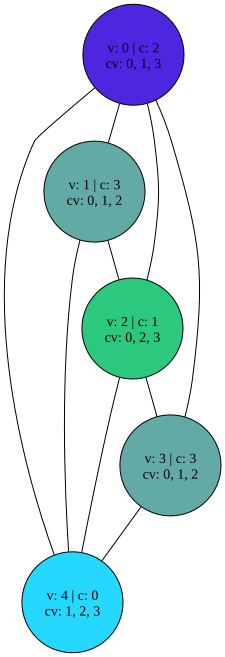


---------------------
  Execução Carvalho
---------------------
Solution:
Objective value = 4 cores
Cores usadas: [ 0, 1, 2, 3, | 4, ]
Cores dos vértices (vértice: cor): 
| v0: z0 | v1: z3 | v2: z1 | v3: z3 | v4: z2 |

Advanced usage:
Problem solved in 10.000000 milliseconds
Problem solved in 0.010 s
Problem solved in 5 iterations
Problem solved in 1 branch-and-bound nodes


In [4]:
p = 0.8
G = nx.gnp_random_graph(5, p)

print(f"----------\n\
|V| =  {len(G.nodes())}\n\
P   = {p}\n\
----------\n")
Rodrigues(G, True)
print("")
Carvalho(G)